# Продуктовый и бизнес-анализ интернет-магазина косметики (3,53 млн событий)

**Цель проекта:** провести сквозной анализ пользовательского поведения, воронки продаж, сезонности и клиентских сегментов на основе логов событий за декабрь 2019 года (3 533 286 событий, 358 212 уникальных пользователей).

**Стек и архитектура:**
* **PostgreSQL + SQLAlchemy:** хранение 3,53 млн записей, индексация и перенос тяжелых агрегаций на сторону СУБД (push-down computation) для экономии оперативной памяти.
* **Python (Pandas, Matplotlib):** обработка итоговых витрин и визуализация продуктовых метрик.


In [1]:
%pip install psycopg2-binary sqlalchemy pandas matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
from sqlalchemy import create_engine, text
import time


DB_USER = 'postgres'
DB_PASS = 'password'
DB_HOST = 'localhost'
DB_PORT = '5432'
DB_NAME = 'ecommerce_pet'

engine = create_engine(f'postgresql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}')


# file_path = '2019-Dec.csv.zip'
# table_name = 'events_dec'

# chunk_size = 200_000
# start_time = time.time()
# total_rows = 0



# for i, chunk in enumerate(pd.read_csv(file_path, chunksize=chunk_size)):
#     chunk['event_time'] = pd.to_datetime(chunk['event_time']).dt.tz_localize(None)
#     mode = 'replace' if i == 0 else 'append'
#     chunk.to_sql(table_name, engine, if_exists=mode, index=False, method='multi')

#     total_rows += len(chunk)
#     print(f"Загружено строк: {total_rows:,} ({round(time.time() - start_time, 1)} сек.)")


# with engine.begin() as conn:
#     conn.execute(text(f"CREATE INDEX idx_{table_name}_user ON {table_name} (user_id);"))
#     conn.execute(text(f"CREATE INDEX idx_{table_name}_type ON {table_name} (event_type);"))
#     conn.execute(text(f"CREATE INDEX idx_{table_name}_time ON {table_name} (event_time);"))




In [3]:
query_eda = """
SELECT 
    event_type,
    COUNT(*) AS total_events,
    COUNT(DISTINCT user_id) AS unique_users,
    COUNT(DISTINCT user_session) AS unique_sessions,
    COUNT(*) FILTER (WHERE price <= 0 OR price IS NULL) AS zero_or_negative_price,
    COUNT(*) FILTER (WHERE user_session IS NULL) AS null_sessions,
    ROUND(AVG(price)::numeric, 2) AS avg_price
FROM events_dec
GROUP BY event_type
ORDER BY total_events DESC;
"""

df_eda = pd.read_sql(query_eda, engine)
display(df_eda)


,event_type,total_events,unique_users,unique_sessions,zero_or_negative_price,null_sessions,avg_price
0,view,1728331,358212,794416,6067,5,12.64
1,cart,927124,83458,165295,1207,648,5.26
2,remove_from_cart,664655,45217,84614,315,126,5.32
3,purchase,213176,25613,28894,18,0,5.06


In [5]:

query_clean = """
SELECT 
    event_type,
    COUNT(*) AS total_rows,
    COUNT(*) FILTER (WHERE price < 0) AS negative_price,
    COUNT(*) FILTER (WHERE price = 0) AS zero_price,
    COUNT(*) FILTER (WHERE price IS NULL) AS null_price,
    COUNT(*) FILTER (WHERE category_code IS NULL) AS null_category,
    COUNT(*) FILTER (WHERE brand IS NULL) AS null_brand
FROM events_dec
GROUP BY event_type;
"""

df_clean = pd.read_sql(query_clean, engine)
display(df_clean)


query_zero_purchases = """
SELECT *
FROM events_dec
WHERE event_type = 'purchase' AND (price <= 0 OR price IS NULL)
LIMIT 20;
"""

df_zero_purchases = pd.read_sql(query_zero_purchases, engine)
display(df_zero_purchases)


,event_type,total_rows,negative_price,zero_price,null_price,null_category,null_brand
0,cart,927124,0,1207,0,916380,403305
1,purchase,213176,18,0,0,210470,91695
2,remove_from_cart,664655,0,315,0,658386,296236
3,view,1728331,0,6067,0,1689585,719053


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-12-06 08:44:06 UTC,purchase,5670257,1487580014042939619,None,None,-15.87,410016187,2414f145-f7fa-473f-9d74-41e5694178a0
1,2019-12-08 12:38:35 UTC,purchase,5670257,1487580014042939619,None,None,-15.87,579811230,001d3051-07af-1cef-f5e4-10443d9742b9
2,2019-12-13 08:44:49 UTC,purchase,5716859,1487580014042939619,None,None,-47.62,414087247,6617078d-899a-4b89-8538-b70e505bff38
3,2019-12-13 13:48:10 UTC,purchase,5716857,1487580014042939619,None,None,-23.81,584773479,a3f156d9-b7fc-444d-8899-920715cca75d
4,2019-12-17 10:37:03 UTC,purchase,5670257,1487580014042939619,None,None,-15.87,584498077,ecbf0f7c-3c10-42e8-9af6-1397b5428afa
5,2019-12-17 10:37:03 UTC,purchase,5716855,1487580014042939619,None,None,-7.94,584498077,ecbf0f7c-3c10-42e8-9af6-1397b5428afa
6,2019-12-17 13:31:01 UTC,purchase,5670257,1487580014042939619,None,None,-15.87,513455730,efd60b1a-f616-4f48-a5d2-1a1ab0bd61e1
7,2019-12-20 17:56:16 UTC,purchase,5716859,1487580014042939619,None,None,-47.62,589538798,094f5f94-e7d2-4d05-a722-dbc2015c0351
8,2019-12-22 19:31:01 UTC,purchase,5716859,1487580014042939619,None,None,-47.62,590958276,42953b86-32c5-4861-8760-e9c2cd35a609
9,2019-12-25 13:01:21 UTC,purchase,5716861,1487580014042939619,None,None,-79.37,489184067,af1b35db-1024-495e-8c42-b959491ba136


In [6]:
query_brands = """
SELECT 
    COALESCE(brand, 'unknown') AS brand,
    COUNT(*) FILTER (WHERE event_type = 'view') AS views,
    COUNT(*) FILTER (WHERE event_type = 'cart') AS carts,
    COUNT(*) FILTER (WHERE event_type = 'remove_from_cart') AS removes,
    COUNT(*) FILTER (WHERE event_type = 'purchase') AS purchases,
    ROUND(SUM(price) FILTER (WHERE event_type = 'purchase')::numeric, 2) AS revenue,
    ROUND(AVG(price) FILTER (WHERE event_type = 'purchase')::numeric, 2) AS avg_price,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE event_type = 'purchase') / 
        NULLIF(COUNT(*) FILTER (WHERE event_type = 'view'), 0), 2
    ) AS conversion_rate
FROM events_dec
WHERE price > 0
GROUP BY COALESCE(brand, 'unknown')
ORDER BY revenue DESC NULLS LAST
LIMIT 15;
"""

df_brands = pd.read_sql(query_brands, engine)
display(df_brands)


,brand,views,carts,removes,purchases,revenue,avg_price,conversion_rate
0,unknown,712995,402098,295921,91677,440747.25,4.81,12.86
1,runail,108092,80411,49510,18199,58177.26,3.20,16.84
2,grattol,83257,37841,26651,8171,43793.50,5.36,9.81
3,irisk,66529,45841,29565,10583,35291.51,3.33,15.91
4,uno,20343,10567,7817,2780,29084.76,10.46,13.67
5,estel,44300,17946,10287,4116,24474.19,5.95,9.29
6,jessnail,34913,8450,5197,1823,24075.00,13.21,5.22
7,strong,8966,720,499,120,22266.41,185.55,1.34
8,masura,50363,33788,34049,6985,19809.19,2.84,13.87
9,cnd,20275,6180,3776,1299,19378.92,14.92,6.41


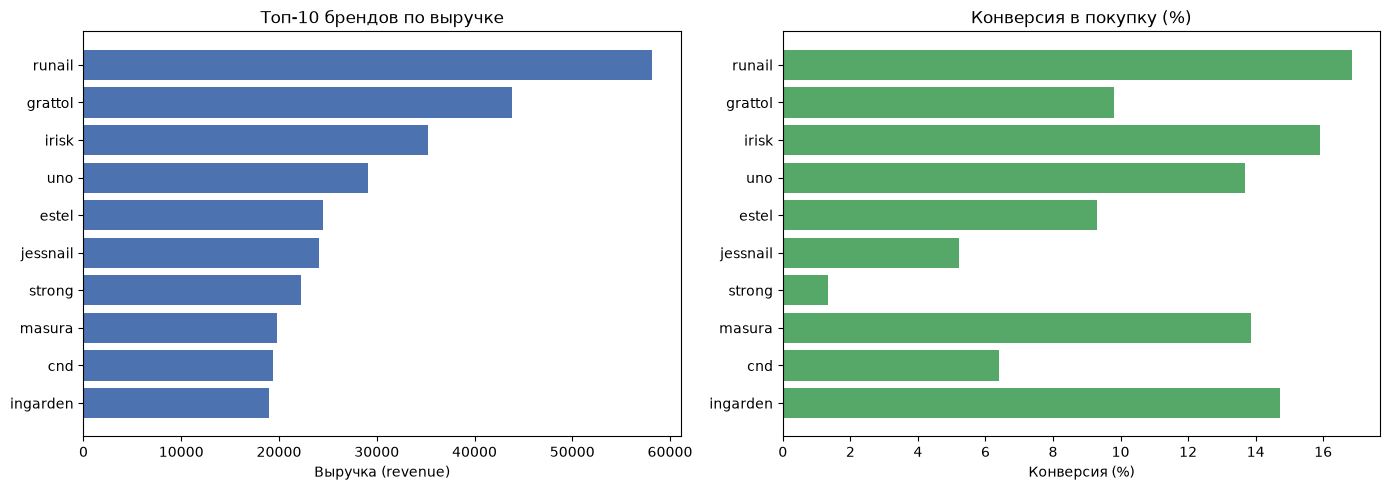

In [7]:
import matplotlib.pyplot as plt


top_brands = df_brands[df_brands['brand'] != 'unknown'].head(10).iloc[::-1]


fig, axes = plt.subplots(1, 2, figsize=(14, 5))


axes[0].barh(top_brands['brand'], top_brands['revenue'], color='#4C72B0')
axes[0].set_title('Топ-10 брендов по выручке')
axes[0].set_xlabel('Выручка (revenue)')


axes[1].barh(top_brands['brand'], top_brands['conversion_rate'], color='#55A868')
axes[1].set_title('Конверсия в покупку (%)')
axes[1].set_xlabel('Конверсия (%)')


plt.tight_layout()
plt.show()


,hour,views,purchases,revenue,conversion_rate
0,0,17797,2003,9636.26,11.25
1,1,14167,1648,7476.77,11.63
2,2,15248,1995,10307.71,13.08
3,3,21361,2734,12358.51,12.80
4,4,32402,3321,16504.53,10.25
5,5,48544,6068,31958.19,12.50
6,6,65800,8496,42302.97,12.91
7,7,79156,10869,55203.83,13.73
8,8,88523,11880,62614.66,13.42
9,9,93158,12642,66211.30,13.57


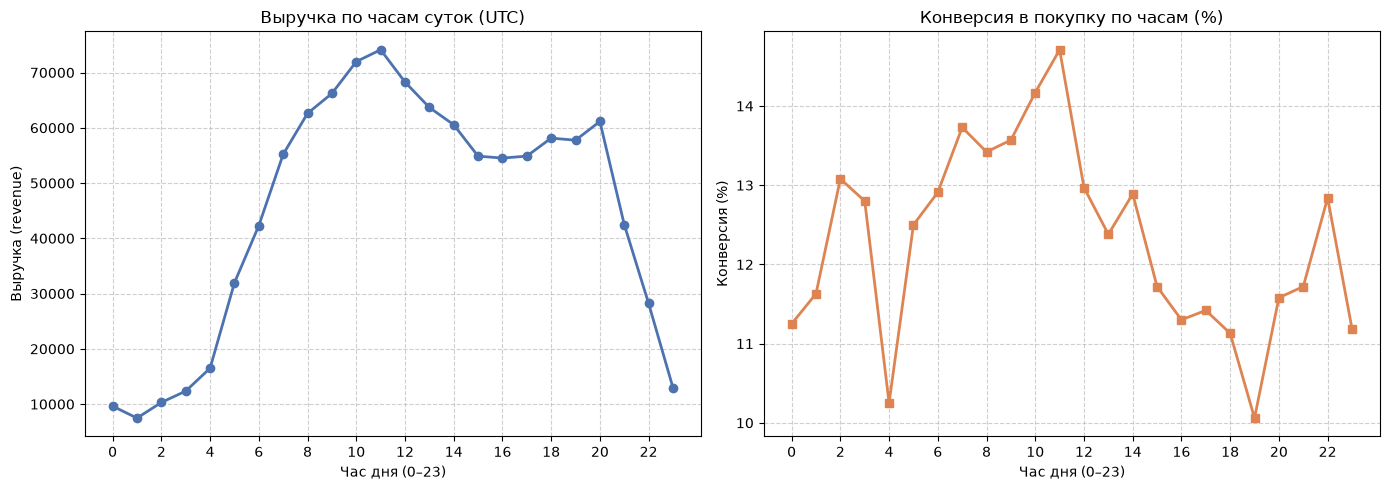

In [8]:
query_hourly = """
SELECT 
    EXTRACT(HOUR FROM event_time::timestamp)::int AS hour,
    COUNT(*) FILTER (WHERE event_type = 'view') AS views,
    COUNT(*) FILTER (WHERE event_type = 'purchase') AS purchases,
    ROUND(SUM(price) FILTER (WHERE event_type = 'purchase')::numeric, 2) AS revenue,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE event_type = 'purchase') / 
        NULLIF(COUNT(*) FILTER (WHERE event_type = 'view'), 0), 2
    ) AS conversion_rate
FROM events_dec
WHERE price > 0
GROUP BY hour
ORDER BY hour;
"""

df_hourly = pd.read_sql(query_hourly, engine)
display(df_hourly.head(10))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


axes[0].plot(df_hourly['hour'], df_hourly['revenue'], marker='o', color='#4C72B0', linewidth=2)
axes[0].set_title('Выручка по часам суток (UTC)')
axes[0].set_xlabel('Час дня (0–23)')
axes[0].set_ylabel('Выручка (revenue)')
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True, linestyle='--', alpha=0.6)


axes[1].plot(df_hourly['hour'], df_hourly['conversion_rate'], marker='s', color='#DD8452', linewidth=2)
axes[1].set_title('Конверсия в покупку по часам (%)')
axes[1].set_xlabel('Час дня (0–23)')
axes[1].set_ylabel('Конверсия (%)')
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()



In [9]:
query_users = """
WITH user_stats AS (
    SELECT 
        user_id,
        COUNT(*) AS items_bought,
        COUNT(DISTINCT user_session) AS orders_count,
        SUM(price) AS total_spent
    FROM events_dec
    WHERE event_type = 'purchase' AND price > 0
    GROUP BY user_id
)
SELECT 
    CASE 
        WHEN items_bought = 1 THEN '1 товар (разовый)'
        WHEN items_bought BETWEEN 2 AND 5 THEN '2-5 товаров (обычный)'
        WHEN items_bought BETWEEN 6 AND 15 THEN '6-15 товаров (активный)'
        ELSE '16+ товаров (оптовик / мастер)'
    END AS customer_segment,
    COUNT(*) AS users_count,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS users_share_pct,
    ROUND(SUM(total_spent)::numeric, 2) AS segment_revenue,
    ROUND((100.0 * SUM(total_spent) / SUM(SUM(total_spent)) OVER ())::numeric, 2) AS revenue_share_pct,
    ROUND(AVG(total_spent)::numeric, 2) AS avg_ltv
FROM user_stats
GROUP BY customer_segment
ORDER BY segment_revenue DESC;
"""

df_users = pd.read_sql(query_users, engine)
display(df_users)


,customer_segment,users_count,users_share_pct,segment_revenue,revenue_share_pct,avg_ltv
0,6-15 товаров (активный),9013,35.19,391181.28,36.28,43.40
1,16+ товаров (оптовик / мастер),3310,12.92,358029.33,33.21,108.17
2,2-5 товаров (обычный),10380,40.53,251848.55,23.36,24.26
3,1 товар (разовый),2910,11.36,77105.37,7.15,26.50


,event_date,views,purchases,revenue
0,2019-12-01,59152,7236,32701.10
1,2019-12-02,64325,9079,43304.28
2,2019-12-03,63234,8217,38703.91
3,2019-12-04,65219,8371,41233.50
4,2019-12-05,61084,7767,37379.70


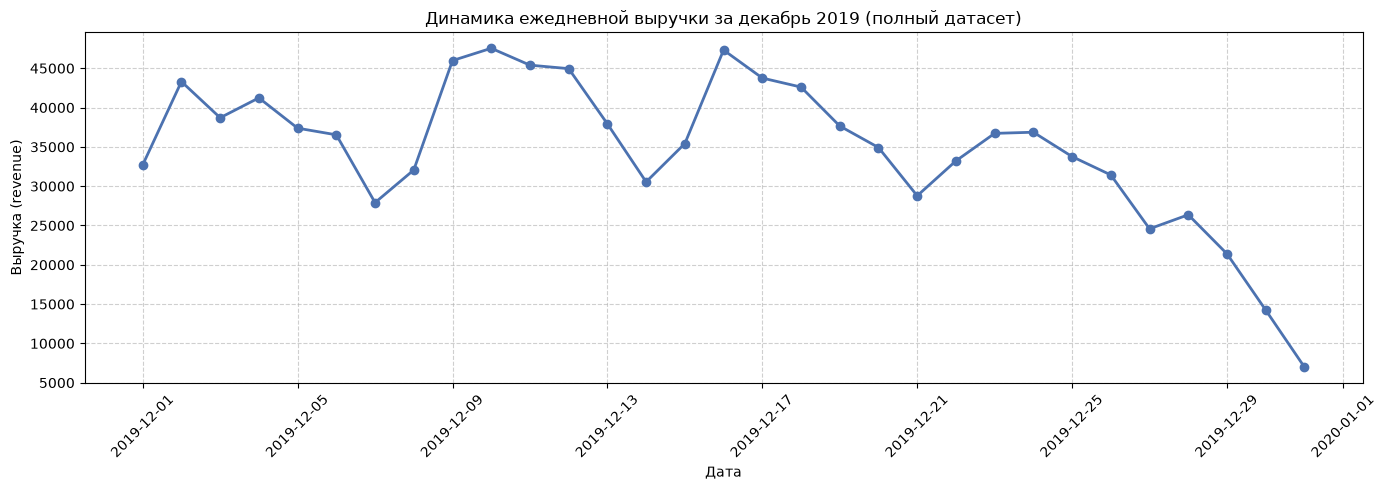

In [10]:
query_daily = """
SELECT 
    DATE(event_time::timestamp) AS event_date,
    COUNT(*) FILTER (WHERE event_type = 'view') AS views,
    COUNT(*) FILTER (WHERE event_type = 'purchase') AS purchases,
    ROUND(SUM(price) FILTER (WHERE event_type = 'purchase')::numeric, 2) AS revenue
FROM events_dec
WHERE price > 0
GROUP BY event_date
ORDER BY event_date;
"""

df_daily = pd.read_sql(query_daily, engine)
display(df_daily.head())


plt.figure(figsize=(14, 5))
plt.plot(df_daily['event_date'], df_daily['revenue'], marker='o', color='#4C72B0', linewidth=2)
plt.title('Динамика ежедневной выручки за декабрь 2019 (полный датасет)')
plt.xlabel('Дата')
plt.ylabel('Выручка (revenue)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## Ключевые выводы и рекомендации для бизнеса

1. **Воронка и качество данных:** из 358 212 пользователей, просматривавших товары, в корзину добавили позиции 83 458 человек (23,3%), а покупку совершили 25 613 покупателей (общая конверсия 7,15%). В данных выявлено ~98,3% пропусков в текстовых категориях (`category_code`) и 42,7% в брендах (`brand`), а также 18 возвратов/корректировок с отрицательной ценой в одной категории.
2. **Влияние брендов и ценового сегмента:** товары без указанного бренда (`unknown`) принесли **440 747** выручки (40,9% от всего оборота — критическая точка роста для заполнения карточек каталога). Среди известных брендов лидируют бюджетные расходники **runail** (выручка 58 177, конверсия 16,84%), **grattol** (43 793) и **irisk** (35 291, конверсия 15,91%). Дорогое оборудование (**strong**, **marathon** со средним чеком 138–186) ожидаемо имеет низкую конверсию (1,3–1,7%).
3. **Сегментация клиентов (мастера против розницы):** 12,92% покупателей (3 310 оптовиков/мастеров, берущих 16+ позиций) генерируют **33,21% всей выручки** (358 029) со средним LTV **108.17**. Суммарно активные закупщики (6+ товаров — 48,11% покупателей) приносят **69,49%** оборота магазина (749 210). *Рекомендация:* внедрить накопительную систему скидок и оптовые наборы для мастеров маникюра.
4. **Сезонность и пики спроса:** выявлена четкая недельная цикличность (спады по субботам и пики закупок в понедельник–вторник), предновогодний максимум в середине месяца (9–16 декабря) и резкий спад после 25 декабря. Внутри дня основной объем выручки приходится на рабочие/дневные часы, а конверсия стабильно держится на уровне 11–13,7%. *Рекомендация:* планировать промо-рассылки на вечер воскресенья / утро понедельника и смещать основные акции на первую половину декабря.
